<a href="https://colab.research.google.com/github/jossykings/preventing-catastrophic-forgetting-using-experience-replay-and-EWC/blob/main/ewc_three_tasks_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EWC on three CICIDS2018 tasks (fixed version)

**What was wrong in the previous notebook and what changed**

| # | Problem | Fix |
|---|---|---|
| 1 | Task C was loaded from Task 2's file (`csv_path` instead of `csv_path_3`) and split with `stratify=y_task2`, so **B and C were the same data** | Every task is loaded by one function, `load_balanced(path)`, with its own stratification |
| 2 | `RobustScaler` leaves features with IQR = 0 unscaled, so inputs reached 1e6 to 1e8 (epoch-1 loss was 10,508) and the logits saturated | Signed `log1p`, then standardise, then clip to ±5 |
| 3 | One scaler per task, so the same flow looked different in each task | **One shared preprocessor, fitted on Task A only** (a deployed model can't know the task) |
| 4 | inf/NaN cleaned *after* scaling | Cleaned *before* anything else |
| 5 | Fisher rescaled to mean 1, which erased its scale and made `LAM` meaningless | Raw Fisher, **λ chosen on a validation split** with a sweep |
| 6 | `.head(n)` sampling took only the earliest rows of a chronological file | Random sampling per chunk |
| 7 | λ was a guess | λ sweep on validation data, reported on test data |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score

try:                                   # Colab: mount Drive. Elsewhere: skip.
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

SEED = 42
BASE = 'drive/MyDrive/Tasks_Binary'    # folder holding our data
## tasks paths
PATHS = {'A': f'{BASE}/Task_1.csv', 'B': f'{BASE}/Task_2.csv', 'C': f'{BASE}/Task_3.csv'}
## names of each tasks
NAMES = ['A', 'B', 'C']
## columns not needed, so the model wouldnt overfit
DROP_COLS = ['Binary_Label', 'Label', 'Timestamp', 'Dst Port'] ## columns to be dropped

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Load the three tasks

In [3]:
def clean_frame(df):
    """Strip column names, force numeric, remove inf/NaN rows. Done BEFORE scaling."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    num = [c for c in df.columns if c not in ('Label', 'Timestamp')]
    df[num] = df[num].apply(pd.to_numeric, errors='coerce')
    return df.replace([np.inf, -np.inf], np.nan).dropna()

def load_balanced(path, per_class=200_000, chunk_size=100_000, keep_frac=0.5, seed=SEED):
    """Stream a big CSV, randomly keep `keep_frac` of each class per chunk
    (so we don't only get the start of a chronological file), then balance 50/50."""
    parts = []
    for i, chunk in enumerate(pd.read_csv(path, chunksize=chunk_size)):
        chunk = clean_frame(chunk)
        parts.append(chunk.groupby('Binary_Label', group_keys=False)
                          .sample(frac=keep_frac, random_state=seed + i))
    allr = pd.concat(parts, ignore_index=True)
    n = int(min(per_class, allr['Binary_Label'].value_counts().min()))
    bal = allr.groupby('Binary_Label', group_keys=False).sample(n=n, random_state=seed)
    return bal.sample(frac=1, random_state=seed).reset_index(drop=True)

## functions above used to load the data sents into A, B and C
dfA = clean_frame(pd.read_csv(PATHS['A']))
dfB = load_balanced(PATHS['B'])
dfC = load_balanced(PATHS['C'])

FRAMES = {'A': dfA, 'B': dfB, 'C': dfC}
for n in NAMES:
    print(f"Task {n}: {len(FRAMES[n]):,} rows | attack share {FRAMES[n]['Binary_Label'].mean():.2f}")
    print('   ', FRAMES[n]['Label'].value_counts().to_dict())

Task A: 1,274,526 rows | attack share 0.52
    {'Benign': 611783, 'DoS attacks-Hulk': 434873, 'SSH-Bruteforce': 117322, 'DoS attacks-GoldenEye': 41455, 'FTP-BruteForce': 39346, 'DoS attacks-SlowHTTPTest': 19462, 'DoS attacks-Slowloris': 10285}
Task B: 400,000 rows | attack share 0.50
    {'Benign': 200000, 'DDOS attack-HOIC': 107258, 'DDoS attacks-LOIC-HTTP': 92404, 'DDOS attack-LOIC-UDP': 286, 'Brute Force -Web': 38, 'SQL Injection': 7, 'Brute Force -XSS': 7}
Task C: 400,000 rows | attack share 0.50
    {'Benign': 200000, 'Bot': 127494, 'Infilteration': 72506}


## 2. Split + one shared preprocessor

`signed log1p → StandardScaler (fit on Task A train only) → clip ±5`. Flags stay 0/1, `Protocol` is divided by 17.
Each task's training split also gets a 10% **validation** slice, used only to choose λ.

In [4]:
def xy(df):
    return df.drop(columns=DROP_COLS, errors='ignore'), df['Binary_Label'].astype('float32')

## one fixed order for every columns, no haphazard
cols = list(xy(dfA)[0].columns)

RAW = {}
for n in NAMES:
    X, y = xy(FRAMES[n]); X = X[cols]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    if n == 'A':                                     # Task A: use a 30% sample to train on, as before
        Xtr, _, ytr, _ = train_test_split(Xtr, ytr, test_size=0.7, stratify=ytr, random_state=SEED)
    RAW[n] = (Xtr, ytr, Xte, yte)

def slog(a):                                         # signed log1p: handles negatives like Init Win Byts = -1
    return np.sign(a) * np.log1p(np.abs(a))


## prep and transform our data
class Prep:
    def fit(self, X):
        flaglike = [c for c in X.columns if c.endswith('Flags') or c.endswith('Flag Cnt')
                    or c in ('Protocol', 'CWE Flag Count')]
        self.cols = list(X.columns)
        self.log_cols = [c for c in X.columns if c not in flaglike and X[c].nunique() > 1]
        self.idx = [self.cols.index(c) for c in self.log_cols]
        self.sc = StandardScaler().fit(slog(X[self.log_cols].to_numpy('float64')))
        return self
    def transform(self, X):
        out = X[self.cols].to_numpy('float32').copy()
        out[:, self.idx] = np.clip(self.sc.transform(slog(out[:, self.idx].astype('float64'))), -5, 5)
        if 'Protocol' in self.cols:
            out[:, self.cols.index('Protocol')] /= 17.0
        assert np.isfinite(out).all()
        return out

prep = Prep().fit(RAW['A'][0])                       # fitted on Task A TRAIN only

TRAIN, VAL, TEST = {}, {}, {}
for n in NAMES:
    Xtr, ytr, Xte, yte = RAW[n]
    a, b = prep.transform(Xtr), ytr.to_numpy('float32')
    a_tr, a_va, b_tr, b_va = train_test_split(a, b, test_size=0.1, stratify=b, random_state=SEED)
    TRAIN[n], VAL[n] = (a_tr, b_tr), (a_va, b_va)
    TEST[n] = (prep.transform(Xte), yte.to_numpy('float32'))

for n in NAMES:
    print(f"Task {n}: train {TRAIN[n][0].shape} | val {VAL[n][0].shape} | test {TEST[n][0].shape} "
          f"| attack share {TRAIN[n][1].mean():.2f} | max|x| = {np.abs(TRAIN[n][0]).max():.1f}")

# Sanity check: tasks must now genuinely differ (before, B and C were identical)
mB, mC = TRAIN['B'][0].mean(0), TRAIN['C'][0].mean(0)
print("\nlargest feature-mean gap between Task B and Task C:", float(np.abs(mB - mC).max()))
assert np.abs(mB - mC).max() > 1e-3, "Task B and C look identical, check the file paths"

Task A: train (275297, 77) | val (30589, 77) | test (254906, 77) | attack share 0.52 | max|x| = 5.0
Task B: train (288000, 77) | val (32000, 77) | test (80000, 77) | attack share 0.50 | max|x| = 5.0
Task C: train (288000, 77) | val (32000, 77) | test (80000, 77) | attack share 0.50 | max|x| = 5.0

largest feature-mean gap between Task B and Task C: 0.49948742985725403


## 3. Model

In [5]:
import tensorflow as tf

def build_model(n_features):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_features,)),
        tf.keras.layers.Dense(128, activation="relu"), tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation="relu"),  tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1),                       # raw logit
    ])

def evaluate(model, X, y):
    p = tf.sigmoid(model.predict(X, batch_size=8192, verbose=0)[:, 0]).numpy()
    pred = (p >= 0.5).astype(int)
    return {"accuracy":  accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall":    recall_score(y, pred, zero_division=0)}

## 4. EWC

* **Fisher** (`compute_fisher`) is now the **raw** diagonal Fisher, averaged over up to 5,000 samples of the task just learned.
  `kind="exact"` uses the Bernoulli form `p(1-p)·(∂logit/∂θ)²`; `kind="empirical"` uses `(p-y)²·(∂logit/∂θ)²`.
  It is no longer rescaled to mean 1, so its scale is meaningful and λ is tuned on validation data instead.
* **Penalty**: `(λ/2) Σ_tasks Σ_params F·(θ − θ*)²`.
* Adam gets `global_clipnorm` so a large λ can't blow up a step.

In [6]:
def compute_fisher(model, X, y, n_samples=5000, batch=100, kind="exact", seed=SEED):
    idx = np.random.RandomState(seed).choice(len(X), min(n_samples, len(X)), replace=False)
    Xs, ys = tf.constant(X[idx]), tf.constant(y[idx])
    variables = model.trainable_variables

    @tf.function(reduce_retracing=True)
    def batch_fisher(xb, yb):
        with tf.GradientTape() as tape:
            z = model(xb, training=False)[:, 0]                          # logits
        jac = tape.jacobian(z, variables)                                # per-sample d logit / d weight
        p = tf.sigmoid(z)
        w = p * (1 - p) if kind == "exact" else tf.square(p - yb)
        return [tf.reduce_sum(tf.reshape(w, [-1] + [1] * (len(j.shape) - 1)) * tf.square(j), axis=0)
                for j in jac]

    fisher = [tf.zeros_like(v) for v in variables]
    for s in range(0, len(Xs), batch):
        fisher = [f + g for f, g in zip(fisher, batch_fisher(Xs[s:s + batch], ys[s:s + batch]))]
    return [f / float(len(Xs)) for f in fisher]                          # RAW Fisher, not rescaled

def fisher_summary(fisher):
    flat = np.concatenate([f.numpy().ravel() for f in fisher])
    top = np.sort(flat)[::-1]
    return (f"Fisher: mean={flat.mean():.3e} max={flat.max():.3e} "
            f"| top 1% of weights hold {top[:max(1, len(top)//100)].sum() / top.sum():.0%} of the mass")

def ewc_penalty(model, fishers, anchors, lam):
    total = tf.constant(0.0)
    for fisher, anchor in zip(fishers, anchors):                         # every earlier task
        for f, a, v in zip(fisher, anchor, model.trainable_variables):
            total += tf.reduce_sum(f * tf.square(v - a))
    return 0.5 * lam * total

def train_task(model, X, y, ewc=False, memory=None, lam=0.0, epochs=5, batch_size=512,
               lr=1e-3, fisher_kind="exact", verbose=True):
    fishers = list(memory["fishers"]) if ewc else []
    anchors = list(memory["anchors"]) if ewc else []
    opt = tf.keras.optimizers.Adam(lr, global_clipnorm=5.0)

    @tf.function
    def step(xb, yb):
        with tf.GradientTape() as tape:
            z = model(xb, training=True)[:, 0]
            ce = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=yb, logits=z))
            pen = ewc_penalty(model, fishers, anchors, lam)              # 0 when there are no earlier tasks
            loss = ce + pen                                              # <- EWC enters HERE
        grads = tape.gradient(loss, model.trainable_variables)
        opt.apply_gradients(zip(grads, model.trainable_variables))
        return ce, pen

    ds = (tf.data.Dataset.from_tensor_slices((X, y)).shuffle(len(X), seed=SEED)
          .batch(batch_size).prefetch(tf.data.AUTOTUNE))
    for epoch in range(epochs):
        ce_sum, pen_sum, n = 0.0, 0.0, 0
        for xb, yb in ds:
            ce, pen = step(xb, yb); ce_sum += float(ce); pen_sum += float(pen); n += 1
        if verbose:
            print(f"    epoch {epoch + 1}/{epochs}  ce={ce_sum / n:.4f}  ewc_penalty={pen_sum / n:.4f}")

    if ewc:                                                              # consolidate this task
        fish = compute_fisher(model, X, y, kind=fisher_kind)
        if verbose: print("    " + fisher_summary(fish))
        memory["fishers"].append(fish)
        memory["anchors"].append([tf.identity(v) for v in model.trainable_variables])

## 5. Run the sequence A → B → C
`eval_sets` is `VAL` while tuning λ and `TEST` for the final numbers. Both runs start from identical weights.

In [7]:
def run_sequence(ewc, lam=0.0, eval_sets=TEST, fisher_kind="exact", epochs=5, verbose=True):
    tf.keras.utils.set_random_seed(SEED)                 # same starting weights for every run
    model = build_model(len(cols))
    memory = {"fishers": [], "anchors": []}
    rows = []
    for trained in NAMES:
        if verbose: print(f"  Training on Task {trained}  (ewc={ewc}, lam={lam:g})")
        train_task(model, *TRAIN[trained], ewc=ewc, memory=memory, lam=lam,
                   fisher_kind=fisher_kind, epochs=epochs, verbose=verbose)
        for tested in NAMES:
            rows.append({"trained_through": trained, "tested_on": tested,
                         **evaluate(model, *eval_sets[tested])})
    return pd.DataFrame(rows)

### λ sweep on the **validation** split
Score = mean accuracy over A, B, C after the last task (i.e. how well the final model remembers everything).
The test set is not touched here.

In [8]:
LAMBDAS = [1, 10, 100, 1e3, 1e4, 1e5, 1e6]
FISHER_KINDS = ["exact", "empirical"]

sweep = []
for kind in FISHER_KINDS:
    for lam in LAMBDAS:
        r = run_sequence(True, lam=lam, eval_sets=VAL, fisher_kind=kind, verbose=False)
        f = r[r.trained_through == "C"].set_index("tested_on")
        sweep.append({"fisher": kind, "lam": lam,
                      "avg_acc": f.accuracy.mean(), "acc_A": f.loc["A", "accuracy"],
                      "acc_B": f.loc["B", "accuracy"], "acc_C": f.loc["C", "accuracy"],
                      "recall_A": f.loc["A", "recall"]})
        print(f"{kind:9s} lam={lam:<9g} avg_acc={sweep[-1]['avg_acc']:.3f}  "
              f"A={sweep[-1]['acc_A']:.3f} B={sweep[-1]['acc_B']:.3f} C={sweep[-1]['acc_C']:.3f}")

sweep = pd.DataFrame(sweep)
best = sweep.loc[sweep.avg_acc.idxmax()]
BEST_LAM, BEST_KIND = float(best.lam), best.fisher
display(sweep.round(3))
print(f"\nChosen on validation: fisher={BEST_KIND}, lam={BEST_LAM:g}")

exact     lam=1         avg_acc=0.779  A=0.845 B=0.646 C=0.845
exact     lam=10        avg_acc=0.763  A=0.818 B=0.627 C=0.844
exact     lam=100       avg_acc=0.795  A=0.846 B=0.697 C=0.843
exact     lam=1000      avg_acc=0.899  A=0.915 B=0.940 C=0.841
exact     lam=10000     avg_acc=0.918  A=0.990 B=0.930 C=0.835
exact     lam=100000    avg_acc=0.911  A=0.977 B=0.945 C=0.812
exact     lam=1e+06     avg_acc=0.896  A=0.987 B=0.947 C=0.753
empirical lam=1         avg_acc=0.757  A=0.787 B=0.639 C=0.845
empirical lam=10        avg_acc=0.760  A=0.801 B=0.634 C=0.844
empirical lam=100       avg_acc=0.758  A=0.771 B=0.660 C=0.843
empirical lam=1000      avg_acc=0.835  A=0.848 B=0.814 C=0.842
empirical lam=10000     avg_acc=0.827  A=0.859 B=0.782 C=0.840
empirical lam=100000    avg_acc=0.905  A=0.956 B=0.925 C=0.836
empirical lam=1e+06     avg_acc=0.906  A=0.976 B=0.915 C=0.828


,fisher,lam,avg_acc,acc_A,acc_B,acc_C,recall_A
0,exact,1.0,0.779,0.845,0.646,0.845,0.705
1,exact,10.0,0.763,0.818,0.627,0.844,0.656
2,exact,100.0,0.795,0.846,0.697,0.843,0.710
3,exact,1000.0,0.899,0.915,0.940,0.841,0.845
4,exact,10000.0,0.918,0.990,0.930,0.835,0.991
5,exact,100000.0,0.911,0.977,0.945,0.812,1.000
6,exact,1000000.0,0.896,0.987,0.947,0.753,1.000
7,empirical,1.0,0.757,0.787,0.639,0.845,0.595
8,empirical,10.0,0.760,0.801,0.634,0.844,0.624
9,empirical,100.0,0.758,0.771,0.660,0.843,0.566



Chosen on validation: fisher=exact, lam=10000


## 6. Final comparison on the held-out TEST sets

In [9]:
print("=== WITHOUT EWC ===");  res_plain = run_sequence(False, eval_sets=TEST)
print(f"\n=== WITH EWC (fisher={BEST_KIND}, lam={BEST_LAM:g}) ===")
res_ewc = run_sequence(True, lam=BEST_LAM, eval_sets=TEST, fisher_kind=BEST_KIND)

=== WITHOUT EWC ===
  Training on Task A  (ewc=False, lam=0)
    epoch 1/5  ce=0.0598  ewc_penalty=0.0000
    epoch 2/5  ce=0.0136  ewc_penalty=0.0000
    epoch 3/5  ce=0.0119  ewc_penalty=0.0000
    epoch 4/5  ce=0.0113  ewc_penalty=0.0000
    epoch 5/5  ce=0.0112  ewc_penalty=0.0000
  Training on Task B  (ewc=False, lam=0)
    epoch 1/5  ce=0.1279  ewc_penalty=0.0000
    epoch 2/5  ce=0.0149  ewc_penalty=0.0000
    epoch 3/5  ce=0.0124  ewc_penalty=0.0000
    epoch 4/5  ce=0.0116  ewc_penalty=0.0000
    epoch 5/5  ce=0.0111  ewc_penalty=0.0000
  Training on Task C  (ewc=False, lam=0)
    epoch 1/5  ce=0.5138  ewc_penalty=0.0000
    epoch 2/5  ce=0.3429  ewc_penalty=0.0000
    epoch 3/5  ce=0.3355  ewc_penalty=0.0000
    epoch 4/5  ce=0.3323  ewc_penalty=0.0000
    epoch 5/5  ce=0.3299  ewc_penalty=0.0000

=== WITH EWC (fisher=exact, lam=10000) ===
  Training on Task A  (ewc=True, lam=10000)
    epoch 1/5  ce=0.0598  ewc_penalty=0.0000
    epoch 2/5  ce=0.0136  ewc_penalty=0.0000
    

### After Task A only

In [10]:
display(res_plain[res_plain.trained_through == "A"].drop(columns="trained_through").set_index("tested_on").round(3))

,accuracy,precision,recall
tested_on,,,
A,0.998,0.997,1.000
B,0.499,0.000,0.000
C,0.501,0.642,0.005


### Every stage, every test set (red = no EWC, green = EWC; dashed line = when that task was learned)

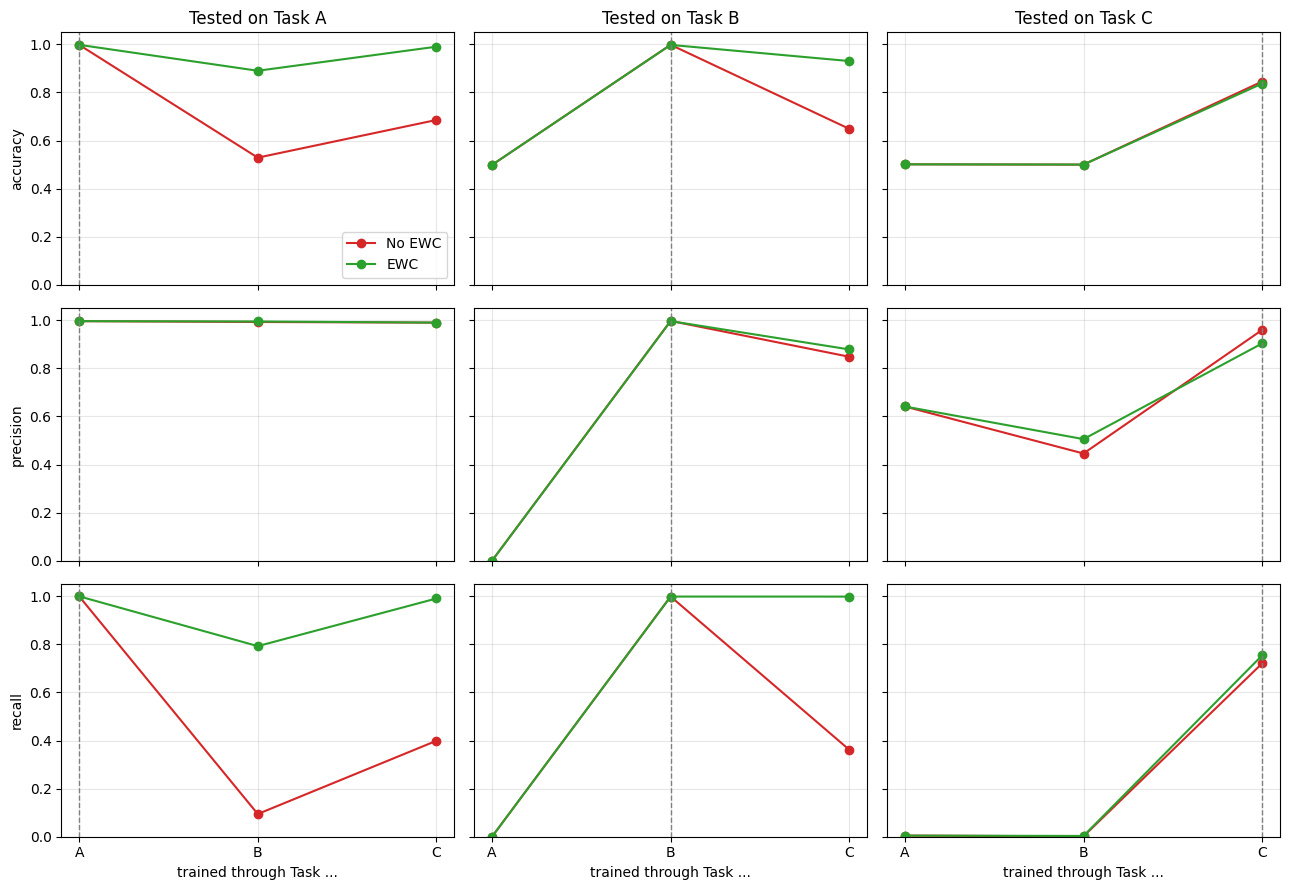

In [11]:
metrics = ["accuracy", "precision", "recall"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True, sharey=True)
for i, m in enumerate(metrics):
    for j, t in enumerate(NAMES):
        ax = axes[i, j]
        for label, df, col in (("No EWC", res_plain, "tab:red"), ("EWC", res_ewc, "tab:green")):
            d = df[df.tested_on == t]
            ax.plot(d.trained_through, d[m], "o-", c=col, label=label)
        ax.axvline(j, ls="--", c="gray", lw=1)
        ax.set_ylim(0, 1.05); ax.grid(alpha=.3)
        if i == 0: ax.set_title(f"Tested on Task {t}")
        if j == 0: ax.set_ylabel(m)
        if i == 2: ax.set_xlabel("trained through Task ...")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

### Final result after all three tasks

In [12]:
both = pd.concat({"No EWC": res_plain, "EWC": res_ewc}, names=["method"]).reset_index(level=0)
last = both[both.trained_through == "C"].pivot(index="tested_on", columns="method", values=metrics)
last.loc["average"] = last.mean()
display(last.round(3))

accuracy        precision        recall       
method         EWC No EWC       EWC No EWC    EWC No EWC
tested_on                                               
A            0.990  0.685     0.991  0.990  0.991  0.399
B            0.931  0.649     0.879  0.848  0.999  0.362
C            0.837  0.845     0.904  0.960  0.754  0.721
average      0.919  0.726     0.924  0.933  0.915  0.494

### How much did each earlier task lose?

In [ ]:
rows = []
for label, df in (("No EWC", res_plain), ("EWC", res_ewc)):
    for t in ["A", "B"]:
        just = df[(df.trained_through == t) & (df.tested_on == t)].iloc[0]
        end  = df[(df.trained_through == "C") & (df.tested_on == t)].iloc[0]
        rows.append({"method": label, "task": t,
                     "accuracy just learned": just.accuracy, "accuracy after C": end.accuracy,
                     "accuracy lost": just.accuracy - end.accuracy,
                     "recall just learned": just.recall, "recall after C": end.recall,
                     "recall lost": just.recall - end.recall})
display(pd.DataFrame(rows).set_index(["method", "task"]).round(3))